# Numerical Errors: Roundoff, Cancellation, and Conditioning

Computers store real numbers approximately. The examples below compute roundoff, cancellation, and linear-system errors for the Linear Algebra Review lecture. The final experiment separates the error from rounding the data from the error of solving the stored system. For derivations, see Higham, *Accuracy and Stability of Numerical Algorithms*, 2nd ed. (2002), Chapters 1–2 and Theorems 7.1–7.2, pp.120–121; Watkins, *Fundamentals of Matrix Computations*, 2nd ed. (2002), Chapter2. Numerical results are from the displayed run; library implementations can change the final digits.

In [1]:
import warnings
import numpy as np
from scipy import linalg
from decimal import Decimal, getcontext

# scipy warns about the very ill-conditioned matrices in Section 4; we report K(A) ourselves.
warnings.filterwarnings("ignore", category=linalg.LinAlgWarning)
import mpmath as mp

## 1. Machine epsilon and unit roundoff

For a nonzero real $x$ rounded to binary64 with round-to-nearest, with no overflow or underflow, $\mathrm{fl}(x)=x(1+\delta)$ and $|\delta|\le u$. This relative-error model does not cover all subnormal values.

* `eps` $=2^{-52}\approx2.2\cdot10^{-16}$ is the spacing from $1$ to the next larger binary64 number.
* Unit roundoff is $u=2^{-53}\approx1.1\cdot10^{-16}$. The absolute spacing changes with the exponent; `eps` is not the smallest positive number that can be represented.

See Higham (2002), Theorem 2.2, p.38.

In [2]:
eps = np.finfo(float).eps
u = eps / 2
print(f"eps = {eps:.3e} = 2^-52: {eps == 2.0**-52}")
print(f"np.spacing(1.0) = {np.spacing(1.0):.3e}")
print(f"u   = {u:.3e} = 2^-53: {u == 2.0**-53}")

eps = 2.220e-16 = 2^-52: True
np.spacing(1.0) = 2.220e-16
u   = 1.110e-16 = 2^-53: True


The spacing grows with the size of the number, so the *relative* spacing $\text{spacing}(x)/x$ varies between $u$ and $2u$ ($=$ `eps`).

In [3]:
for x in [1.0, 1.5, 1.99, 2.0, 1e3, 1e8]:
    print(f"x = {x:>8.2f}   spacing(x) = {np.spacing(x):.3e}   spacing(x)/x = {np.spacing(x)/x:.3e}")

x =     1.00   spacing(x) = 2.220e-16   spacing(x)/x = 2.220e-16
x =     1.50   spacing(x) = 2.220e-16   spacing(x)/x = 1.480e-16
x =     1.99   spacing(x) = 2.220e-16   spacing(x)/x = 1.116e-16
x =     2.00   spacing(x) = 4.441e-16   spacing(x)/x = 2.220e-16
x =  1000.00   spacing(x) = 1.137e-13   spacing(x)/x = 1.137e-16
x = 100000000.00   spacing(x) = 1.490e-08   spacing(x)/x = 1.490e-16


Adding `eps` to $1$ gives the next stored number. Adding $u$ is a tie halfway between two stored numbers, and the round-to-even rule returns $1$.

In [4]:
print("1 + u   == 1 :", 1.0 + u == 1.0)
print("1 + eps == 1 :", 1.0 + eps == 1.0)

1 + u   == 1 : True
1 + eps == 1 : False


## 2. Cancellation

Subtracting two nearly equal numbers cancels the digits they share. Consider $(1-\cos x)/x^2$, whose true value tends to $1/2$ as $x \to 0$. The identity $1-\cos x = 2\sin^2(x/2)$ gives the same function without a subtraction.

In [5]:
print(f"{'x':>8}  {'(1-cos x)/x^2':>16}  {'2 sin^2(x/2)/x^2':>18}")
for k in range(1, 9):
    x = 10.0**(-k)
    naive = (1 - np.cos(x)) / x**2
    stable = 2 * np.sin(x / 2)**2 / x**2
    print(f"{x:8.0e}  {naive:16.12f}  {stable:18.12f}")

       x     (1-cos x)/x^2    2 sin^2(x/2)/x^2
   1e-01    0.499583472197      0.499583472197
   1e-02    0.499995833347      0.499995833347
   1e-03    0.499999958326      0.499999958333
   1e-04    0.499999996961      0.499999999583
   1e-05    0.500000041370      0.499999999996
   1e-06    0.500044450291      0.500000000000
   1e-07    0.499600361081      0.500000000000
   1e-08    0.000000000000      0.500000000000


At $x=10^{-8}$, inspect the next cell: depending on the library, the naive formula can return zero or another inaccurate result. If `np.cos(x)` rounds to exactly $1$, subtraction returns zero. The mathematical function is close to $1/2$. Rewriting the expression avoids subtracting nearby rounded values; this example does not establish that every library transcendental function is correctly rounded.

In [6]:
x = 1e-8
print("np.cos(1e-8) == 1.0 :", np.cos(x) == 1.0)
print("naive  :", (1 - np.cos(x)) / x**2)
print("stable :", 2 * np.sin(x / 2)**2 / x**2)

np.cos(1e-8) == 1.0 : True
naive  : 0.0
stable : 0.5


## 3. The quadratic formula

For $x^2 + 10^8 x + 1 = 0$ the small root is close to $-10^{-8}$. The usual formula subtracts two nearly equal numbers, because $\sqrt{b^2 - 4ac} \approx b$. Multiplying numerator and denominator by the conjugate gives an equivalent formula that only adds two positive numbers:

$$
x = \frac{-b + \sqrt{b^2-4ac}}{2a} = \frac{-2c}{b + \sqrt{b^2-4ac}} .
$$

The problem is well conditioned; only the formula is unstable. We use 50-digit decimal arithmetic to get a reference value.

In [7]:
a, b, c = 1.0, 1e8, 1.0
disc = np.sqrt(b**2 - 4*a*c)
x_formula = (-b + disc) / (2*a)
x_conj    = -2*c / (b + disc)

getcontext().prec = 50
A, B, C = Decimal(1), Decimal(10)**8, Decimal(1)
x_ref = float((-2*C) / (B + (B**2 - 4*A*C).sqrt()))

print(f"{'method':<22}{'small root':>22}{'relative error':>18}")
for name, val in [("quadratic formula", x_formula), ("conjugate rewrite", x_conj)]:
    print(f"{name:<22}{val:22.15e}{abs(val - x_ref)/abs(x_ref):18.2e}")
print(f"{'reference (50 digits)':<22}{x_ref:22.15e}")

method                            small root    relative error
quadratic formula     -7.450580596923828e-09          2.55e-01
conjugate rewrite     -1.000000000000000e-08          0.00e+00
reference (50 digits) -1.000000000000000e-08


The quadratic formula returns $-7.45 \times 10^{-9}$, which has an error of about $25\%$. The conjugate rewrite is correct to about machine precision. Same problem, same condition number, two algebraically identical formulas.

(linear-system-errors)=
## 4. Forward error, backward error, and conditioning

Let $\mathbf{Ax}=\mathbf{b}\ne\mathbf{0}$ with nonsingular square $\mathbf{A}$. Here $\mathbf{x}$ denotes the exact solution for the **stored entries** of $\mathbf{A}$ and $\mathbf{b}$; all norms are 2-norms. For a computed $\hat{\mathbf{x}}$, the exact residual is $\mathbf{r}=\mathbf{b}-\mathbf{A}\hat{\mathbf{x}}$.

![Forward error compares answers; matrix-only backward error changes the stored matrix so the computed solution solves a nearby system exactly.](../../media/figures/la-forward-backward.png)

The **relative forward error** is $\|\hat{\mathbf{x}}-\mathbf{x}\|_2/\|\mathbf{x}\|_2$. Allowing perturbations only in $\mathbf{A}$ gives the **backward error**

$$\eta_A=\frac{\|\mathbf{r}\|_2}{\|\mathbf{A}\|_2\|\hat{\mathbf{x}}\|_2}.$$

Indeed, $\|\mathbf{r}\|_2\le\|\Delta\mathbf{A}\|_2\|\hat{\mathbf{x}}\|_2$ for any admissible perturbation; equality is attained with $\Delta\mathbf{A}=\mathbf{r}\hat{\mathbf{x}}^\mathsf{T}/\|\hat{\mathbf{x}}\|_2^2$. This proves Higham's Theorem 7.1 in the matrix-only 2-norm case. Allowing simultaneous relative perturbations in both $\mathbf{A}$ and $\mathbf{b}$ instead gives denominator $\|\mathbf{A}\|_2\|\hat{\mathbf{x}}\|_2+\|\mathbf{b}\|_2$.

With $K_2=\|\mathbf{A}\|_2\|\mathbf{A}^{-1}\|_2$, two valid forward bounds are

$$\begin{aligned}
\frac{\|\hat{\mathbf{x}}-\mathbf{x}\|_2}{\|\mathbf{x}\|_2}&\le K_2\frac{\|\mathbf{r}\|_2}{\|\mathbf{b}\|_2},\\
\frac{\|\hat{\mathbf{x}}-\mathbf{x}\|_2}{\|\mathbf{x}\|_2}&\le\frac{K_2\eta_A}{1-K_2\eta_A}\quad\text{if }K_2\eta_A<1.
\end{aligned}$$

The first follows from $\mathbf{x}-\hat{\mathbf{x}}=\mathbf{A}^{-1}\mathbf{r}$ and $\|\mathbf{b}\|_2\le\|\mathbf{A}\|_2\|\mathbf{x}\|_2$. For the second, first bound the error by $K_2\eta_A\|\hat{\mathbf{x}}\|_2$, then use $\|\hat{\mathbf{x}}\|_2\le\|\mathbf{x}\|_2+\|\hat{\mathbf{x}}-\mathbf{x}\|_2$ and rearrange. Thus $K_2\eta_A$ alone is a first-order rule, not this finite bound. Theorems 7.1–7.2, pp.120–121, specify the perturbation model.

### Hilbert experiment: distinguish assembly error and solve error

Choose $\mathbf{x}_0=\mathbf{1}$ and form `b = A @ x0` in binary64 using the stored Hilbert matrix. Because this multiplication rounds, $\mathbf{x}_0$ need not solve the stored system exactly. The cell converts every stored binary64 value exactly to a high-precision number. At 100 decimal digits it solves that stored system, evaluates its residual, and computes singular values. It repeats the calculation at 160 digits to check reference convergence. These are numerical high-precision checks, not interval-certified bounds.

`assembly` measures $\|\mathbf{x}-\mathbf{x}_0\|_2/\|\mathbf{x}_0\|_2$; `forward` measures the solve error relative to $\mathbf{x}$. `res64` is the normalized residual evaluated in ordinary binary64, while `resHP` evaluates the residual of the same stored data and solution in high precision. A printed zero in `res64` need not mean the exact residual is zero. `A-bound` is shown only when $K_2\eta_A<1$; `b-bound` is $K_2\|\mathbf{r}\|_2/\|\mathbf{b}\|_2$.

### Push addition errors back onto the operands

Assume both additions stay in the normal floating-point range and satisfy the round-to-nearest model above. If $\widehat s=\mathrm{fl}(\mathrm{fl}(x+y)+z)$, then for $|\delta_1|,|\delta_2|\le u$,

$$
\begin{aligned}
\widehat s&=((x+y)(1+\delta_1)+z)(1+\delta_2)\\
&=x(1+\epsilon_1)+y(1+\epsilon_2)+z(1+\epsilon_3).
\end{aligned}
$$

where $\epsilon_1=\epsilon_2=\delta_1+\delta_2+\delta_1\delta_2$ and $\epsilon_3=\delta_2$. Hence $|\epsilon_1|,|\epsilon_2|\le2u+u^2$ and $|\epsilon_3|\le u$. The computed sum is the exact sum of slightly perturbed operands. This is a backward-error interpretation, even when cancellation makes the relative forward error large compared with the small exact sum. A different association can produce a different computed sum. See Watkins (2002), §2.5, for this operand-perturbation approach.


In [8]:
def stored_system_errors(A, b, xhat, digits):
    """Reference the exact binary64 entries, evaluated at `digits` decimals."""
    with mp.workdps(digits):
        Am = mp.matrix([[mp.mpf(float(value)) for value in row] for row in A])
        bm = mp.matrix([mp.mpf(float(value)) for value in b])
        hm = mp.matrix([mp.mpf(float(value)) for value in xhat])
        xm = mp.lu_solve(Am, bm)
        singular = mp.svd(Am, compute_uv=False)
        normA, sigma_min = singular[0], singular[len(singular)-1]
        condition = normA / sigma_min
        residual = mp.norm(bm - Am * hm)
        forward = mp.norm(hm - xm) / mp.norm(xm)
        assembly = mp.norm(xm - mp.ones(len(b), 1)) / mp.sqrt(len(b))
        eta = residual / (normA * mp.norm(hm))
        rel_residual = residual / mp.norm(bm)
        product = condition * eta
        b_bound = condition * rel_residual
        a_bound = product / (1-product) if product < 1 else None
        assert forward <= b_bound * (1 + mp.mpf('1e-60')) + mp.mpf('1e-70')
        if a_bound is not None:
            assert forward <= a_bound * (1 + mp.mpf('1e-60')) + mp.mpf('1e-70')
        values = dict(condition_2=condition, backward_A=eta, forward=forward,
                      assembly=assembly, relative_residual_high_precision=rel_residual,
                      bound_b=b_bound, bound_A=a_bound)
        return {key: None if val is None else float(val) for key, val in values.items()}

rows = []
for n in range(2, 13):
    A = linalg.hilbert(n)
    x0 = np.ones(n)
    b = A @ x0
    xhat = linalg.solve(A, b)
    measured = stored_system_errors(A, b, xhat, 100)
    repeated = stored_system_errors(A, b, xhat, 160)
    for key in measured:
        if measured[key] is None:
            assert repeated[key] is None
        else:
            assert np.isclose(measured[key], repeated[key], rtol=1e-12, atol=1e-65)
    measured.update(n=n, A=A.tolist(), b=b.tolist(), xhat=xhat.tolist(),
                    relative_residual_binary64=float(np.linalg.norm(b-A @ xhat) / np.linalg.norm(b)))
    rows.append(measured)

print(f"{'n':>2} {'K2':>10} {'assembly':>10} {'forward':>10} {'eta_A':>10} {'res64':>10} {'resHP':>10} {'b-bound':>10} {'A-bound':>10}")
for row in rows:
    a_bound_text = 'n/a' if row['bound_A'] is None else f"{row['bound_A']:.2e}"
    print(f"{row['n']:2d} {row['condition_2']:10.2e} {row['assembly']:10.2e} "
          f"{row['forward']:10.2e} {row['backward_A']:10.2e} "
          f"{row['relative_residual_binary64']:10.2e} {row['relative_residual_high_precision']:10.2e} "
          f"{row['bound_b']:10.2e} {a_bound_text:>10}")

 n         K2   assembly    forward      eta_A      res64      resHP    b-bound    A-bound
 2   1.93e+01   5.27e-16   1.11e-16   3.26e-17   0.00e+00   3.41e-17   6.58e-16   6.29e-16
 3   5.24e+02   9.44e-15   5.38e-15   2.76e-17   0.00e+00   2.97e-17   1.56e-14   1.45e-14
 4   1.55e+04   3.47e-13   4.55e-15   2.51e-17   0.00e+00   2.75e-17   4.27e-13   3.89e-13
 5   4.77e+05   1.07e-12   2.66e-12   7.29e-17   1.06e-16   8.14e-17   3.88e-11   3.47e-11
 6   1.50e+07   2.16e-10   8.84e-11   4.37e-17   7.09e-17   4.94e-17   7.39e-10   6.53e-10
 7   4.75e+08   8.56e-09   9.11e-09   4.13e-17   7.66e-17   4.73e-17   2.25e-08   1.96e-08
 8   1.53e+10   3.14e-07   7.04e-08   2.11e-17   6.56e-17   2.44e-17   3.72e-07   3.21e-07
 9   4.93e+11   8.11e-06   3.11e-06   8.26e-17   1.37e-16   9.64e-17   4.75e-05   4.07e-05
10   1.60e+13   2.88e-04   4.62e-05   2.67e-17   1.03e-16   3.14e-17   5.03e-04   4.28e-04
11   5.22e+14   4.30e-03   9.50e-04   3.92e-17   7.07e-17   4.64e-17   2.42e-02   2.09e-02

Read the measured errors and both bounds together. Increasing condition number permits a larger forward error even when the backward error is small, but a large condition number does not force every solve to be inaccurate. The assembly column exposes error introduced before the solve. Comparing `res64` and `resHP` shows why an ordinary computed residual is an estimate of the exact residual.

The assertions compare forward error with the appropriate bounds for the stored problem. They do not compare it with $K_2\eta_A$ alone. A small measured backward error supports the quality of this solve; a proof of backward stability for an algorithm requires an error analysis over its input class. The high-precision singular values also avoid using a binary64 condition-number estimate as the reference at the binary64 precision limit.

**Activity.** Find a row where the binary64 residual is zero or substantially smaller than the high-precision residual. Explain why this does not contradict the forward-error bound. Then distinguish the assembly error from the error introduced by the linear solver.

In [9]:
import sys
import matplotlib.pyplot as plt
if 'google.colab' in sys.modules:
    import urllib.request
    urllib.request.urlretrieve('https://raw.githubusercontent.com/ndcbe/optimization/main/notebooks/helper.py', 'helper.py')
else:
    sys.path.insert(0, '../')
import helper
helper.set_plotting_style()
results = {'rows': rows, 'reference_digits': [100, 160],
           'reference_problem': 'exact entries of stored binary64 A and b',
           'norm': 'induced matrix 2-norm and vector 2-norm'}
helper.save_results('la-numerical-errors', results,
    notebook='notebooks/6-dev/Numerical-Errors.ipynb',
    source_cells=[('notebooks/6-dev/Numerical-Errors.ipynb', 'results:la-numerical-errors'),
                  ('notebooks/6-dev/Numerical-Errors.ipynb', 'results:la-errors-archive')],
    description='Hilbert stored-system forward/backward errors, high-precision residuals and finite bounds',
    solver='SciPy solve; mpmath references at 100 and 160 decimal digits', quiet=True)

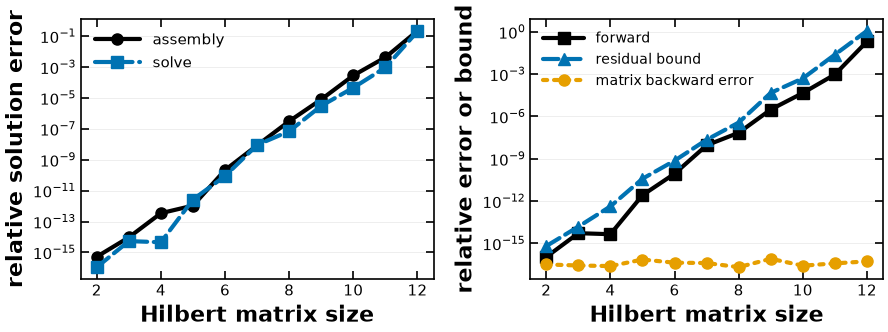

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.5))
data = results['rows']
sizes = [row['n'] for row in data]
series = [('assembly', 'assembly', 'o', '-'), ('forward', 'solve', 's', '--')]
for key, label, marker, style in series:
    axes[0].semilogy(sizes, [max(row[key], 1e-20) for row in data],
                     marker=marker, linestyle=style, label=label)
axes[0].set(ylabel='relative solution error', xlabel='Hilbert matrix size')
axes[0].legend(fontsize=11)
for key, label, marker, style in [('forward', 'forward', 's', '-'),
                                 ('bound_b', 'residual bound', '^', '--'),
                                 ('backward_A', 'matrix backward error', 'o', ':')]:
    axes[1].semilogy(sizes, [max(row[key], 1e-20) for row in data],
                     marker=marker, linestyle=style, label=label)
axes[1].set(ylabel='relative error or bound', xlabel='Hilbert matrix size')
axes[1].legend(fontsize=10)
for ax in axes:
    ax.set_xticks([2, 4, 6, 8, 10, 12])
    ax.grid(axis='y', alpha=.25)
    ax.tick_params(labelsize=11)
fig.tight_layout()
helper.save_figure(fig, 'la-numerical-errors', quiet=True)
plt.show()

The left panel distinguishes rounding of the right-hand side from the subsequent solve. The right panel compares the solve's forward error, a residual-based forward bound, and matrix-only backward error. Both use the same stored-system reference as the table. The bounds permit error; they do not forecast the exact error. Values at the plotting floor $10^{-20}$ would be clipped for display only; the table and archive retain their measured values.